# Correlation
## 1. What is Correlation?
In statistics and data analysis, **correlation** measures the strength and direction of the relationship between two variables. Understanding these relationships helps us identify patterns, detect dependencies, and make informed data-driven decisions.

Depending on the types of variables being analyzed (**categorical** vs. **numerical**), different statistical techniques, metrics, and visualization methods must be applied.

Below is a quick overview of the analysis conducted on the dataset `ifood-restaurants-november-2020.csv`.

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df = pd.read_csv('./ifood-restaurants-november-2020.csv')

numerical = df.select_dtypes(include=['number']).columns.tolist()
Q1 = df[numerical].quantile(0.25)
Q3 = df[numerical].quantile(0.75)
IQR = Q3 - Q1
dfClean = df[~((df[numerical] < (Q1 - 1.5 * IQR)) | (df[numerical] > (Q3 + 1.5 * IQR))).any(axis=1)]
dfClean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 276066 entries, 6538 to 361445
Data columns (total 11 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   avatar         275836 non-null  object 
 1   category       276066 non-null  object 
 2   delivery_fee   276066 non-null  float64
 3   delivery_time  276066 non-null  int64  
 4   distance       276066 non-null  float64
 5   name           276066 non-null  object 
 6   price_range    276066 non-null  object 
 7   rating         276066 non-null  float64
 8   url            276066 non-null  object 
 9   lat            276066 non-null  float64
 10  long           276066 non-null  float64
dtypes: float64(5), int64(1), object(5)
memory usage: 25.3+ MB


In [ ]:
dfClean = dfClean.drop(['avatar', 'url'], axis=1)
categorical = dfClean.select_dtypes(include=['object']).columns.tolist()

## Numerical vs. Numerical (`Quanti-Quanti`)
To measure the relationship between continuous numerical variables:
- **Pearson / Spearman Correlation (`.corr()`)**: Used to compute a correlation matrix.
  - A correlation coefficient near `+1` indicates a strong positive linear relationship.
  - A coefficient near `-1` indicates a strong negative linear relationship.
  - A coefficient around `0` suggests no linear relationship.

In [ ]:
df[numerical].corr()

,delivery_fee,delivery_time,distance,rating,lat,long
delivery_fee,1.000000,0.198268,0.017506,0.008005,0.036714,-0.006672
delivery_time,0.198268,1.000000,0.008892,-0.076375,-0.012702,0.024998
distance,0.017506,0.008892,1.000000,-0.014038,0.007206,-0.002331
rating,0.008005,-0.076375,-0.014038,1.000000,-0.063096,-0.034734
lat,0.036714,-0.012702,0.007206,-0.063096,1.000000,0.341902
long,-0.006672,0.024998,-0.002331,-0.034734,0.341902,1.000000


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

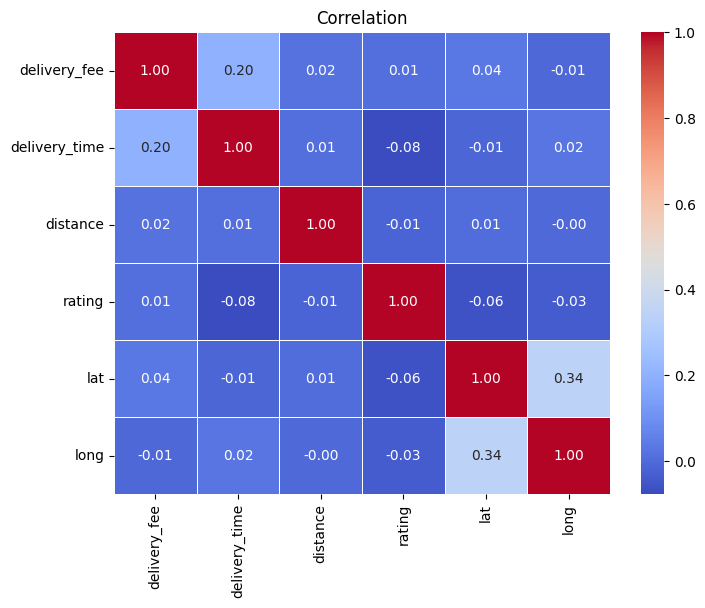

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[numerical].corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation')
plt.show()

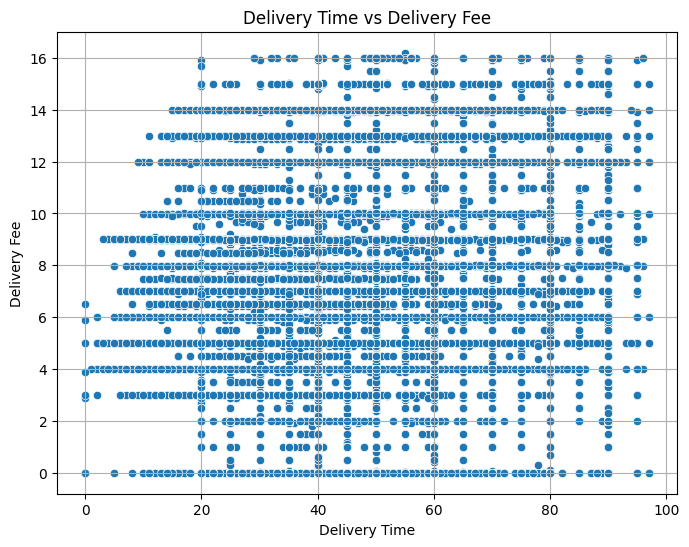

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=dfClean, x='delivery_time', y='delivery_fee')
plt.xlabel('Delivery Time')
plt.ylabel('Delivery Fee')
plt.title('Delivery Time vs Delivery Fee')
plt.grid()
plt.show()

## Categorical vs. Categorical (`Quali-Quali`)
To analyze the relationship between two categorical variables:
- **Cross-tabulation (`crosstab`)**: Used to create contingency tables that display the joint frequency distributions of the categories.
- **Cramér's V**: Calculated as a measure of association strength between nominal categorical variables. Its value ranges from `0` (no association) to `1` (perfect association).

In [ ]:
categorical

['category', 'name', 'price_range']

In [ ]:
df['price_range'].unique()

array(['CHEAP', 'CHEAPEST', 'MODERATE', 'EXPENSIVE', 'MOST_EXPENSIVE'],
      dtype=object)

In [ ]:
len(df['category'].unique())

61

In [ ]:
df['category'].value_counts()

,count
category,
Lanches,89331
Brasileira,67027
Doces & Bolos,34041
Pizza,33797
Açaí,17837
...,...
Colombiana,39
Típica do Norte,27
Paranaense,4


In [ ]:
selectedColumns = ['Lanches', 'Brasileira', 'Doces & Bolos', 'Pizza', 'Açaí', 'Japonesa']
dfSelected = df[df['category'].isin(selectedColumns)]
dfSelected.sample(5)

,avatar,category,delivery_fee,delivery_time,distance,name,price_range,rating,url,lat,long
230963,https://static-images.ifood.com.br/image/uploa...,Brasileira,8.00,60,4.37,Lanches_delivery,CHEAPEST,0.00000,https://www.ifood.com.br/delivery/fortaleza-ce...,-3.71664,-38.5423
120228,https://static-images.ifood.com.br/image/uploa...,Brasileira,11.99,50,6.85,Parada X Restaurante,CHEAPEST,4.10000,https://www.ifood.com.br/delivery/sao-paulo-sp...,-23.56770,-46.6613
204616,https://static-images.ifood.com.br/image/uploa...,Lanches,6.99,50,3.42,Hambúrgueria New York,CHEAPEST,4.70455,https://www.ifood.com.br/delivery/curitiba-pr/...,-25.53130,-49.3031
49132,https://static-images.ifood.com.br/image/uploa...,Lanches,9.90,80,7.81,Chapeleiro Maluco Petiscaria Gourmet,CHEAPEST,4.25000,https://www.ifood.com.br/delivery/rio-de-janei...,-22.98320,-43.2034
192098,https://static-images.ifood.com.br/image/uploa...,Doces & Bolos,10.00,45,1.37,Quem Quer Donuts,MODERATE,4.66667,https://www.ifood.com.br/delivery/ponta-grossa...,-25.09160,-50.1668


In [ ]:
contigency = pd.crosstab(dfSelected['category'], dfSelected['price_range'])
contigency

price_range,CHEAP,CHEAPEST,EXPENSIVE,MODERATE,MOST_EXPENSIVE
category,,,,,
Açaí,1962,15467,40,355,13
Brasileira,7651,48913,2319,6787,1357
Doces & Bolos,3031,28402,608,1802,198
Japonesa,982,4506,2380,3056,1833
Lanches,13446,62984,1972,10419,510
Pizza,4950,14817,3356,9620,1054


In [ ]:
contigency.sum(axis=1)

,0
category,
Açaí,17837
Brasileira,67027
Doces & Bolos,34041
Japonesa,12757
Lanches,89331
Pizza,33797


In [ ]:
contigency.div(contigency.sum(axis=1), axis=0)

price_range,CHEAP,CHEAPEST,EXPENSIVE,MODERATE,MOST_EXPENSIVE
category,,,,,
Açaí,0.109996,0.867130,0.002243,0.019902,0.000729
Brasileira,0.114148,0.729751,0.034598,0.101258,0.020246
Doces & Bolos,0.089040,0.834347,0.017861,0.052936,0.005817
Japonesa,0.076977,0.353218,0.186564,0.239555,0.143686
Lanches,0.150519,0.705063,0.022075,0.116634,0.005709
Pizza,0.146463,0.438412,0.099299,0.284641,0.031186


In [ ]:
from scipy.stats import chi2_contingency

In [ ]:
chi2, p, dot, expected = chi2_contingency(contigency)
n = contigency.sum().sum()
phi2 = chi2 / n
r, k = contigency.shape
cramer_v = np.sqrt(phi2 / (min(r - 1, k - 1) - 1))
print(f'Cramer V: {cramer_v}')

Cramer V: 0.23707734837189226


## To evaluate how a numerical variable behaves across different categories:
- **Grouped Summary Statistics**: Calculated the **mean** and **standard deviation** of `delivery_fee` and `rating` grouped by restaurant category.
- **Data Visualizations**:
  - **Bar Plots**: Used to compare average metric values across categories.
  - **Box Plots**: Used to examine distribution, central tendency, variance, and potential outliers of `rating` across categories.

In [ ]:
dfSelected.groupby('category')[['delivery_fee', 'delivery_time', 'rating']].agg(['mean', 'std'])

delivery_fee           delivery_time               rating  \
                      mean       std          mean        std      mean   
category                                                                  
Açaí              6.016898  4.012580     46.152492  17.560234  3.115370   
Brasileira        6.308089  4.020008     46.907037  17.296640  2.440716   
Doces & Bolos     7.512335  3.743445     46.456831  33.932897  2.546775   
Japonesa          6.453918  4.438290     51.567375  17.597151  3.565887   
Lanches           6.087295  4.000167     49.330803  16.808324  2.781375   
Pizza             5.613014  4.230902     49.878303  16.031969  3.147606   

                         
                    std  
category                 
Açaí           2.192045  
Brasileira     2.248748  
Doces & Bolos  2.387530  
Japonesa       1.872238  
Lanches        2.256607  
Pizza          2.069189

<Axes: xlabel='category'>

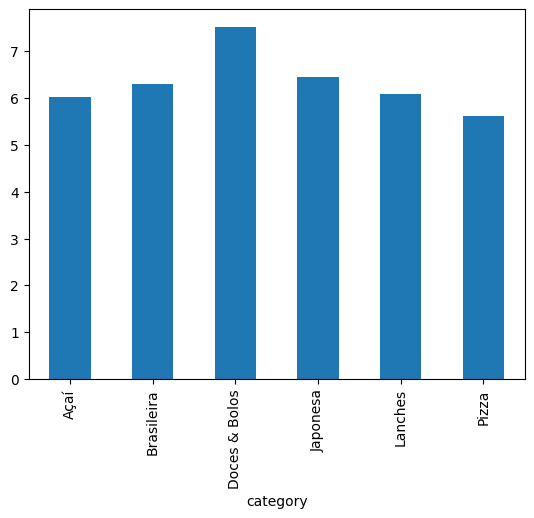

In [ ]:
dfSelected.groupby('category')['delivery_fee'].mean().plot.bar()

<Axes: title={'center': 'rating'}, xlabel='category'>

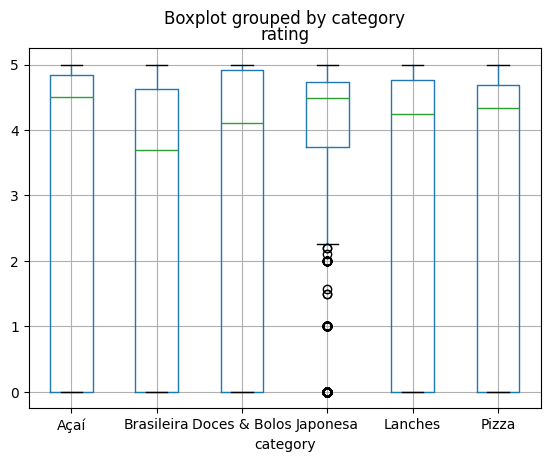

In [ ]:
dfSelected.boxplot(column='rating', by='category')

In [ ]:
df.groupby('price_range')[['delivery_fee', 'rating']].mean()

,delivery_fee,rating
price_range,,
CHEAP,6.075802,3.586457
CHEAPEST,6.319962,2.303163
EXPENSIVE,7.581955,3.971331
MODERATE,6.665889,3.868502
MOST_EXPENSIVE,8.913605,4.133247


<Axes: xlabel='price_range'>

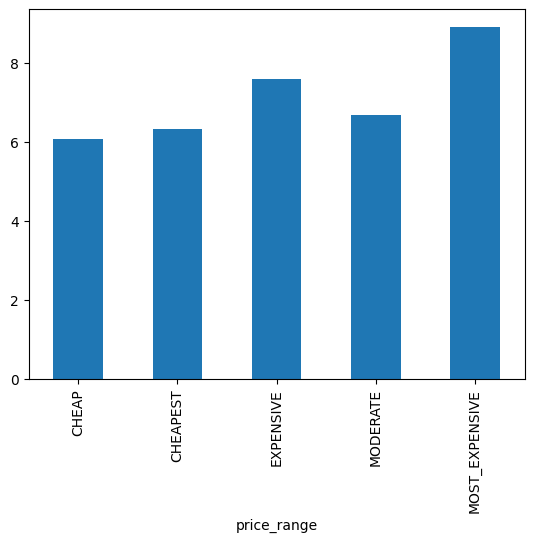

In [ ]:
df.groupby('price_range')['delivery_fee'].mean().plot(kind='bar')